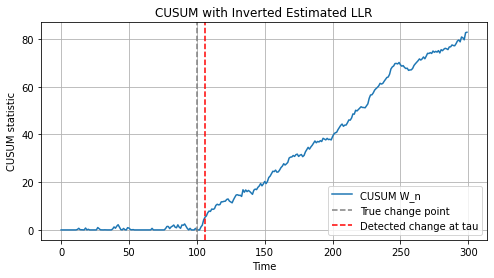

True change point at index: 100
Detected change point at index: 106


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

class LikelihoodRatioEstimator:
    """
    Nonparametric likelihood ratio estimator using RKHS with Gaussian RBF kernel.
    Estimates g(x) ≈ f1(x) / f0(x) from training samples X_p ~ f0 and X_q ~ f1.
    """
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None
        self.n_p = None

    def _build_kernels(self, X_p, X_q):
        self.X_p = X_p
        self.n_p = X_p.shape[0]
        gamma = 1.0 / (2 * self.sigma**2)
        K_pp = rbf_kernel(X_p, X_p, gamma=gamma)
        K_qp = rbf_kernel(X_q, X_p, gamma=gamma)
        return K_pp, K_qp

    def _loss_and_grad(self, alpha, K_pp, K_qp):
        # Evaluate g on Q and P samples
        g_q = K_qp @ alpha
        g_p = K_pp @ alpha
        g_p = np.clip(g_p, 1e-8, None)

        # Loss: E_Q[g] - E_P[log g] + (λ/2) α^T K_pp α
        fit_q = np.mean(g_q)
        fit_p = -np.mean(np.log(g_p))
        reg   = (self.lambda_reg / 2) * (alpha @ (K_pp @ alpha))
        loss = fit_q + fit_p + reg

        # Gradient
        grad_fit_q = np.mean(K_qp, axis=0)
        grad_fit_p = -(K_pp @ (1.0 / g_p)) / self.n_p
        grad_reg   = self.lambda_reg * (K_pp @ alpha)
        grad = grad_fit_q + grad_fit_p + grad_reg

        return loss, grad

    def fit(self, X_p, X_q):
        """
        Fit the estimator using samples X_p ~ f0 and X_q ~ f1.
        """
        K_pp, K_qp = self._build_kernels(X_p, X_q)
        alpha0 = np.ones(self.n_p) / self.n_p
        bounds = [(0, None)] * self.n_p

        result = minimize(
            fun=lambda a: self._loss_and_grad(a, K_pp, K_qp),
            x0=alpha0,
            method='L-BFGS-B',
            jac=True,
            bounds=bounds,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )
        if not result.success:
            msg = result.message.decode() if isinstance(result.message, bytes) else result.message
            raise RuntimeError("Optimization failed: " + msg)

        self.alpha = result.x

    def predict(self, X):
        """
        Predict g(x) = f1(x)/f0(x) for new points X.
        """
        if self.alpha is None:
            raise ValueError("Estimator not fitted yet.")
        gamma = 1.0 / (2 * self.sigma**2)
        K_xp = rbf_kernel(X, self.X_p, gamma=gamma)
        return K_xp @ self.alpha

    def predict_log(self, X):
        """
        Predict log g(x) for new points X.
        """
        g_x = self.predict(X)
        return np.log(np.clip(g_x, 1e-8, None))


class CUSUMDetector:
    """
    Sequential CUSUM detector using an estimated log-likelihood ratio function.
    Here we invert the estimated ratio to ensure log_llr = log(f1/f0).
    """
    def __init__(self, llr_func, threshold):
        """
        llr_func : callable mapping X to log f0/f1 estimates
        threshold : detection threshold b
        """
        self.llr_func = llr_func
        self.threshold = threshold

    def run(self, X_stream):
        """
        Run CUSUM on a sequence of observations X_stream.
        Returns:
          W : array of CUSUM statistics
          tau : detection time (first index where W >= threshold), or None
        """
        n = X_stream.shape[0]
        W = np.zeros(n)
        tau = None

        for i in range(n):
            # Invert the estimated log f0/f1 to get log f1/f0
            log_llr = - self.llr_func(X_stream[i:i+1])[0]
            W[i] = max(0, W[i-1] + log_llr) if i > 0 else max(0, log_llr)
            if tau is None and W[i] >= self.threshold:
                tau = i

        return W, tau


# Example usage
if __name__ == "__main__":
    # 1) Generate training data: f0 ~ N(0,1), f1 ~ N(1,1)
    np.random.seed(0)
    n_train = 300
    X_p = np.random.normal(0, 1, (n_train, 1))
    X_q = np.random.normal(1, 1, (n_train, 1))

    # 2) Train LLR estimator
    lr_est = LikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
    lr_est.fit(X_p, X_q)

    # 3) Set up CUSUM, inverting the estimated log-ratio
    cusum = CUSUMDetector(llr_func=lr_est.predict_log, threshold=5.0)

    # 4) Simulate a data stream with a changepoint at 100
    n_stream = 300
    cp = 100
    stream = np.vstack([
        np.random.normal(0, 1, (cp, 1)),    # pre-change
        np.random.normal(1, 1, (n_stream-cp, 1))  # post-change
    ])

    # 5) Run CUSUM detection
    W, tau = cusum.run(stream)

    # 6) Plot results
    plt.figure(figsize=(8, 4))
    plt.plot(W, label='CUSUM W_n')
    plt.axvline(cp, color='gray', linestyle='--', label='True change point')
    if tau is not None:
        plt.axvline(tau, color='red', linestyle='--', label='Detected change at tau')
    plt.xlabel('Time')
    plt.ylabel('CUSUM statistic')
    plt.title('CUSUM with Inverted Estimated LLR')
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"True change point at index: {cp}")
    print(f"Detected change point at index: {tau}")
